In [1]:
!pip3 install -U ucimlrepo 

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
predict_students_dropout_and_academic_success = fetch_ucirepo(id=697) 
  
# data (as pandas dataframes) 
X = predict_students_dropout_and_academic_success.data.features 
y = predict_students_dropout_and_academic_success.data.targets 
  
# metadata 
print(predict_students_dropout_and_academic_success.metadata) 
  
# variable information 
print(predict_students_dropout_and_academic_success.variables) 


{'uci_id': 697, 'name': "Predict Students' Dropout and Academic Success", 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success', 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv', 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong imbalance towards one of the classes.", 'area': 'Social Sc

In [3]:
!pip3 install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

y = y.squeeze()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
!pip3 install matplotlib
!pip3 install numpy

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

import matplotlib.pyplot as plt
import numpy as np

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

param_grid = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 'auto']
    }
]

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Melhores parâmetros:", grid_search.best_params_)
print("Melhor F1-score (CV):", grid_search.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Melhores parâmetros: {'classifier__C': 10, 'classifier__kernel': 'linear'}
Melhor F1-score (CV): 0.6848459935342116


Acurácia: 0.7536723163841808

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.82      0.69      0.75       284
    Enrolled       0.49      0.41      0.45       159
    Graduate       0.79      0.92      0.85       442

    accuracy                           0.75       885
   macro avg       0.70      0.67      0.68       885
weighted avg       0.75      0.75      0.75       885



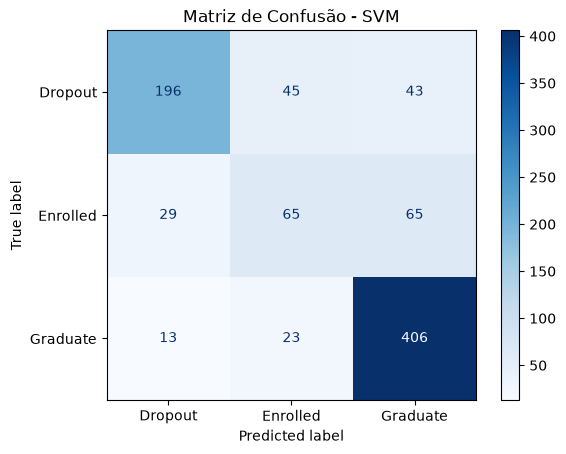

In [ ]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))

disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - SVM')
plt.show()